# EDA — HSE RecSys Challenge 2026

Этап 1 из `notes/plan.md`: разбираем схему всех четырёх файлов и закрываем чеклист по events / user features / item features. Цель — не просто цифры, а решения, которые зафиксируем для этапов 2–3 (валидация и baselines).

Чеклист (`notes/plan.md`, §1):
- **Events**: объём, пользователи, фильмы, типы, диапазон времени, распределения активности, sparsity, распределение оценок, дубликаты, короткие истории, cold/warm.
- **User features**: признаки, пропуски, cardinality, покрытие.
- **Item features**: жанры, пропуски, покрытие, потенциал content-признаков.
- **Submission sample**: формат.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)

# --- данные ---
DATA_DIR = next(
    p for p in (Path('data'), Path('../data'), Path('../../data'))
    if (p / 'events.csv').exists()
)
FILES = {n: DATA_DIR / f'{n}.csv' for n in ('events', 'user_features', 'item_features', 'submission_sample')}
print('DATA_DIR:', DATA_DIR.resolve())

# --- стиль графиков: один hue для односерийных графиков, синяя ordinal-рампа для
# упорядоченных категорий, hairline-сетка, приглушённые оси, текст в ink-токенах ---
INK, INK_2, MUTED = '#0b0b0b', '#52514e', '#898781'
SERIES = '#2a78d6'
GRID, AXIS, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE_ORDINAL_5 = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']
BLUE_ORDINAL_7 = ['#86b6ef', '#6da7ec', '#5598e7', '#3987e5', '#256abf', '#1c5cab', '#104281']

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'DejaVu Sans',
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.edgecolor': AXIS, 'axes.linewidth': 1.0,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.linestyle': '-',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.labelsize': 10, 'axes.titlesize': 12.5,
    'axes.titleweight': 'bold', 'axes.titlepad': 12, 'axes.titlelocation': 'left',
    'figure.dpi': 110,
})


def style(ax, title, grid='y'):
    # заголовок слева + hairline-сетка только по оси значений
    ax.set_title(title)
    other = 'x' if grid == 'y' else 'y'
    ax.grid(axis=grid, visible=True)
    ax.grid(axis=other, visible=False)
    return ax


def kfmt(v):
    # точные числа до 100К, выше — компактные тысячи
    if abs(v) >= 100_000:
        return f'{v / 1000:.0f}K'
    return f'{v:,.0f}'.replace(',', ' ')


print('pandas', pd.__version__, '| numpy', np.__version__)

DATA_DIR: /home/epbichurina/hse_rec_system/data
pandas 3.1.0 | numpy 2.5.4


## 1. Загрузка и схема

In [2]:
events = pd.read_csv(FILES['events'])
users_f = pd.read_csv(FILES['user_features'])
items_f = pd.read_csv(FILES['item_features'])
submission = pd.read_csv(FILES['submission_sample'], dtype={'item_id': str})

for name, df in [('events', events), ('user_features', users_f), ('item_features', items_f), ('submission_sample', submission)]:
    print(f'{name:20s} shape={df.shape}')

na = pd.Series(
    {n: int(d.isna().sum().sum()) for n, d in
     [('events', events), ('user_features', users_f), ('item_features', items_f), ('submission_sample', submission)]},
    name='missing_values',
)
display(na.to_frame())
events.head()

events               shape=(894149, 4)
user_features        shape=(6040, 3)
item_features        shape=(3706, 19)
submission_sample    shape=(6040, 2)


,missing_values
events,0
user_features,0
item_features,0
submission_sample,0


,user_id,item_id,rating,timestamp
0,0,1505,4,0
1,0,3669,3,1
2,0,584,4,2
3,0,3390,3,3
4,0,2885,4,4


## 2. Events: базовые метрики

Считаем объём, число сущностей, sparsity и проверяем дубликаты.

In [3]:
n_events = len(events)
n_users = events.user_id.nunique()
n_items = events.item_id.nunique()

card = pd.Series({
    'interactions': n_events,
    'users': n_users,
    'items (с interaction)': n_items,
    'items (в item_features)': len(items_f),
    'density user-item, %': round(100 * n_events / (n_users * n_items), 2),
    'timestamp min … max': f'{events.timestamp.min()} … {events.timestamp.max()}',
    'rating min … max': f'{events.rating.min()} … {events.rating.max()}',
    'полных дубликатов строк': int(events.duplicated().sum()),
    'повторных пар (user, item)': int(events.duplicated(['user_id', 'item_id']).sum()),
})
card.to_frame()

,0
interactions,894149
users,6040
items (с interaction),3690
items (в item_features),3706
"density user-item, %",4.01
timestamp min … max,0 … 2312
rating min … max,1 … 5
полных дубликатов строк,0
"повторных пар (user, item)",0


Матрица плотная по меркам RecSys (~4% против типичных долей процента), повторных оценок одного фильма нет — каждая пара (user, item) уникальна. Это упрощает бинаризацию feedback и метрики.

## 3. Распределение оценок

,count,"share, %"
rating,,
1,50256,5.62
2,96001,10.74
3,233824,26.15
4,312170,34.91
5,201898,22.58


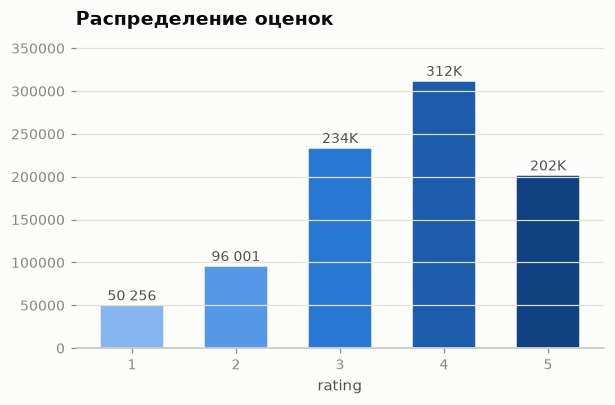

rating >= 3: 83.6% interactions
rating >= 4: 57.5% interactions
rating >= 5: 22.6% interactions


In [4]:
rating_counts = events.rating.value_counts().sort_index()
rating_tbl = pd.DataFrame({
    'count': rating_counts,
    'share, %': (100 * rating_counts / n_events).round(2),
})
display(rating_tbl)

fig, ax = plt.subplots(figsize=(6.2, 3.6))
bars = ax.bar(rating_counts.index.astype(str), rating_counts.values, width=0.62,
              color=BLUE_ORDINAL_5, edgecolor=SURFACE, linewidth=1)
for b, cnt in zip(bars, rating_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + rating_counts.max() * 0.018,
            kfmt(cnt), ha='center', fontsize=9, color=INK_2)
style(ax, 'Распределение оценок')
ax.set_xlabel('rating')
ax.set_ylim(0, rating_counts.max() * 1.14)
plt.show()

for th in (3, 4, 5):
    print(f'rating >= {th}: {(events.rating >= th).mean():.1%} interactions')

Оценки смещены вверх (мода 4). Пороги для бинаризации — содержательная гипотеза H1 из `notes/data.md`:
- `rating >= 3` — ~83.6% interactions (слабое определение «понравилось»);
- `rating >= 4` — ~57.5% (консервативное);
- все оценки как interaction — учит и негатив, что важно для KNN/ALS весов.

## 4. Активность пользователей

,interactions / user
count,6040.000000
mean,148.037914
std,173.461681
min,14.000000
25%,38.000000
50%,84.500000
75%,186.000000
90%,357.000000
99%,818.610000
max,2056.000000


пользователей с < 20 interactions: 269 (4.5%)
пользователей с < 50 interactions: 1998 (33.1%)


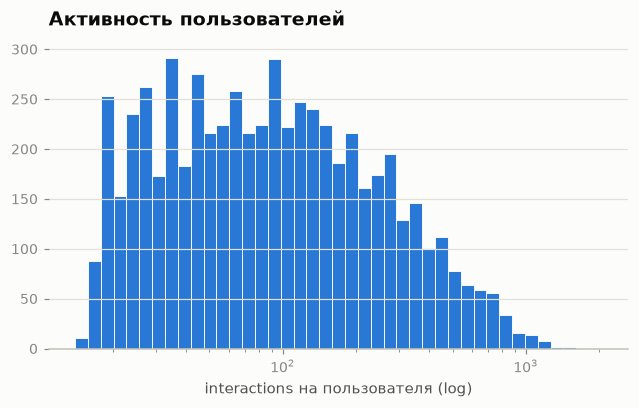

In [5]:
user_act = events.groupby('user_id').size()
display(user_act.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame('interactions / user'))

for th in (20, 50):
    print(f'пользователей с < {th} interactions: {(user_act < th).sum()} ({(user_act < th).mean():.1%})')

fig, ax = plt.subplots(figsize=(6.8, 3.6))
bins = np.logspace(np.log10(user_act.min()), np.log10(user_act.max()), 42)
ax.hist(user_act, bins=bins, color=SERIES, edgecolor=SURFACE, linewidth=0.6)
ax.set_xscale('log')
style(ax, 'Активность пользователей')
ax.set_xlabel('interactions на пользователя (log)')
plt.show()

Холодных пользователей в абсолютном смысле нет: минимум 14 interactions, медиана ~85. Даже после отсечения 10% истории на валидацию у каждого пользователя остаётся длинный train-профиль — персонализация возможна для всех.

## 5. Популярность фильмов

,interactions / item
count,3690.000000
mean,242.316802
std,343.984762
min,1.000000
25%,30.000000
50%,111.000000
75%,315.750000
90%,656.100000
99%,1571.310000
max,3067.000000


фильмов с < 5 interactions: 297 (8.0%)
фильмов с < 10 interactions: 463 (12.5%)
фильмов с < 20 interactions: 712 (19.3%)


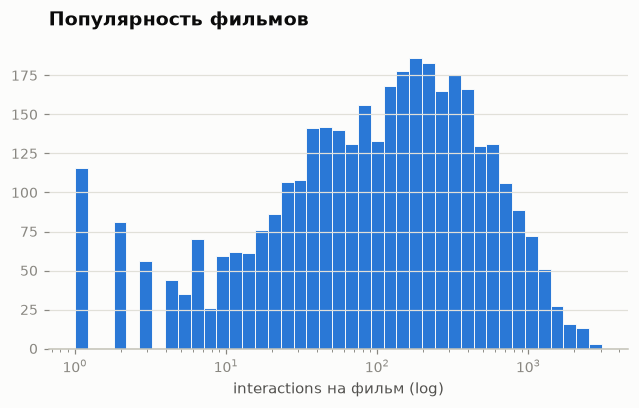

In [6]:
item_pop = events.groupby('item_id').size()
display(item_pop.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame('interactions / item'))
for th in (5, 10, 20):
    n_cold = (item_pop < th).sum()
    print(f'фильмов с < {th} interactions: {n_cold} ({n_cold / len(item_pop):.1%})')

fig, ax = plt.subplots(figsize=(6.8, 3.6))
bins = np.logspace(np.log10(item_pop.min()), np.log10(item_pop.max()), 42)
ax.hist(item_pop, bins=bins, color=SERIES, edgecolor=SURFACE, linewidth=0.6)
ax.set_xscale('log')
style(ax, 'Популярность фильмов')
ax.set_xlabel('interactions на фильм (log)')
plt.show()

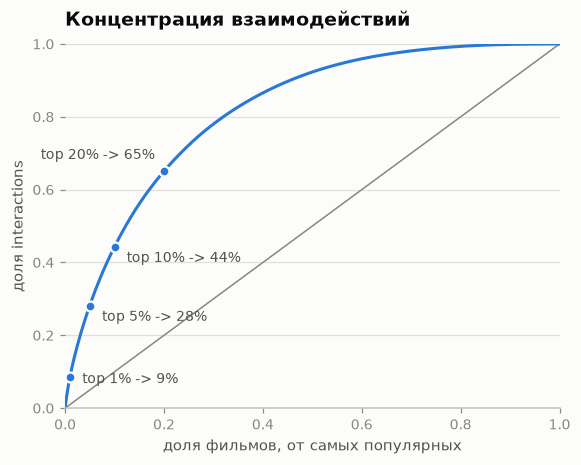

In [7]:
pop_sorted = item_pop.sort_values(ascending=False).values
x = np.arange(1, len(pop_sorted) + 1) / len(pop_sorted)
cum_share = np.cumsum(pop_sorted) / pop_sorted.sum()

fig, ax = plt.subplots(figsize=(5.8, 4.3))
ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1)
ax.plot(x, cum_share, color=SERIES, linewidth=2)
offsets = {0.01: (8, -4), 0.05: (8, -10), 0.10: (8, -10), 0.20: (-6, 8)}
for k, off in offsets.items():
    yv = cum_share[int(k * len(pop_sorted)) - 1]
    ax.plot([k], [yv], 'o', ms=6.5, color=SERIES, mec=SURFACE, mew=1.5)
    ax.annotate(f'top {k:.0%} -> {yv:.0%}', (k, yv), xytext=off,
                textcoords='offset points', fontsize=9, color=INK_2,
                ha='left' if k < 0.2 else 'right')
style(ax, 'Концентрация взаимодействий')
ax.set_xlabel('доля фильмов, от самых популярных')
ax.set_ylabel('доля interactions')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.show()

Сильный long tail: топ-5% фильмов дают ~28% interactions, топ-20% — ~65%. Значит popularity baseline будет заметным, но персонализация и борьба с popularity bias имеют большую комнату — это мотивирует H2 и H3.

## 6. Природа `timestamp` — ключевой вопрос для валидации

План предполагает один глобальный temporal cutoff. Проверяем, является ли timestamp общей календарной осью.

,0
диапазон значений,0 … 2312
пользователей с first timestamp == 0,5471
пользователей с first timestamp <= 4,6040
"corr(n_interactions, max_timestamp)",0.99975
timestamp уникален внутри пользователя,True


,n_events / (max_ts + 1)
count,6040.000000
mean,0.902349
std,0.035990
min,0.695652
50%,0.902439
max,1.000000


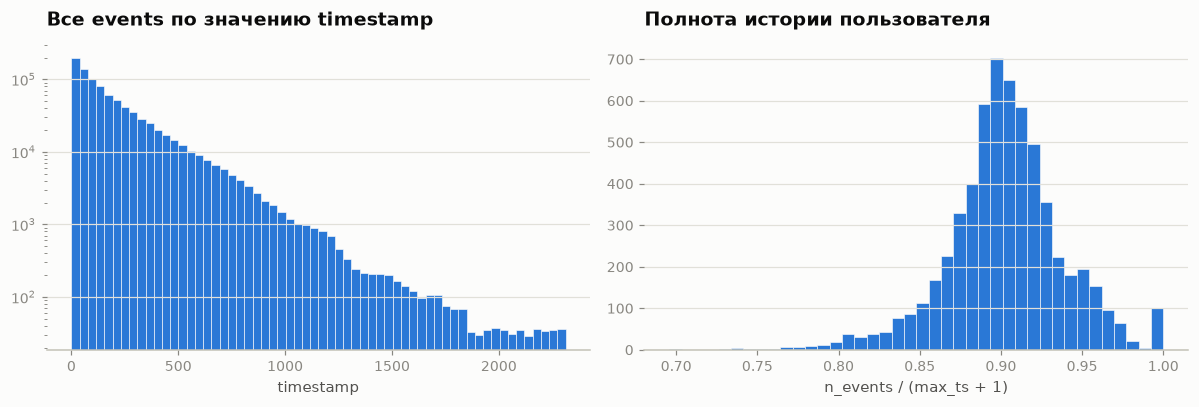

In [8]:
ts_g = events.groupby('user_id').timestamp
first_ts, last_ts, n_ev = ts_g.min(), ts_g.max(), ts_g.size()

checks = pd.Series({
    'диапазон значений': f'{events.timestamp.min()} … {events.timestamp.max()}',
    'пользователей с first timestamp == 0': int((first_ts == 0).sum()),
    'пользователей с first timestamp <= 4': int((first_ts <= 4).sum()),
    'corr(n_interactions, max_timestamp)': round(n_ev.corr(last_ts), 5),
    'timestamp уникален внутри пользователя': bool((ts_g.nunique() == n_ev).all()),
})
display(checks.to_frame())

coverage = n_ev / (last_ts + 1)  # доля наблюдаемых позиций в диапазоне истории пользователя
display(coverage.describe(percentiles=[0.5]).to_frame('n_events / (max_ts + 1)'))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(events.timestamp, bins=60, color=SERIES, edgecolor=SURFACE, linewidth=0.4)
axes[0].set_yscale('log')
style(axes[0], 'Все events по значению timestamp')
axes[0].set_xlabel('timestamp')
axes[1].hist(coverage, bins=40, color=SERIES, edgecolor=SURFACE, linewidth=0.4)
style(axes[1], 'Полнота истории пользователя')
axes[1].set_xlabel('n_events / (max_ts + 1)')
plt.tight_layout()
plt.show()

**Timestamp — это позиция внутри индивидуальной истории пользователя, а не общее календарное время:**
- почти все пользователи начинаются с 0, а внутри пользователя timestamp уникален;
- `corr(n_interactions, max_timestamp) ≈ 1.0` — длина диапазона растёт ровно вместе с числом событий;
- глобальный числовой cutoff по timestamp не делит общее время, а отбирает пользователей с длинными историями (сильный selection bias).

Дополнительное наблюдение: полнота позиций внутри диапазона ≈ 90%, а не 100% — похоже, ~10% исходных взаимодействий замаскированы под скрытый тест. Структура датасета (6040 пользователей, 18 жанров, genres/пол/возраст) практически совпадает с MovieLens ML-1M (~1M оценок, из которых мы видим ~89.4%) — гипотеза про masked test усиливается, но остаётся гипотезой.

**Решение для этапа 2** (аргументы в `notes/data.md` §6): leakage-safe валидация — chronological split **per user** (первые 90% истории -> train, последние 10% -> validation), без общей календарной оси. Ниже — предпросмотр такого сплита.

In [9]:
ev_sorted = events.sort_values(['user_id', 'timestamp'])
rank = ev_sorted.groupby('user_id').cumcount()
n_per_user = ev_sorted.user_id.map(ev_sorted.user_id.value_counts())
# у каждого пользователя holdout = max(1, round(10%)) последних событий
val_start = n_per_user - np.maximum(1, (0.1 * n_per_user).round()).astype(int)
is_val = rank >= val_start
train, val = ev_sorted[~is_val], ev_sorted[is_val]

cold_val_items = set(val.item_id) - set(train.item_id)
split_preview = pd.Series({
    'train interactions': len(train),
    'validation interactions': len(val),
    'пользователей в validation': val.user_id.nunique(),
    'медиана val items / user': int(val.groupby('user_id').size().median()),
    'cold items в validation': len(cold_val_items),
    'interactions с cold items': int(val.item_id.isin(cold_val_items).sum()),
})
split_preview.to_frame()

,0
train interactions,804738
validation interactions,89411
пользователей в validation,6040
медиана val items / user,8
cold items в validation,21
interactions с cold items,27


Все 6040 пользователей имеют ground truth, cold items почти нет — сплит пригоден для Recall@10 без отдельной cold-задачи.

## 7. User features

,user_id,gender,age
0,4855,F,1
1,4065,M,56
2,3331,M,25
3,5373,M,45
4,2032,M,25


,0
пользователей,6040
покрытие пользователей из events,True
gender cardinality,2
age cardinality,7
значения age,"1, 18, 25, 35, 45, 50, 56"


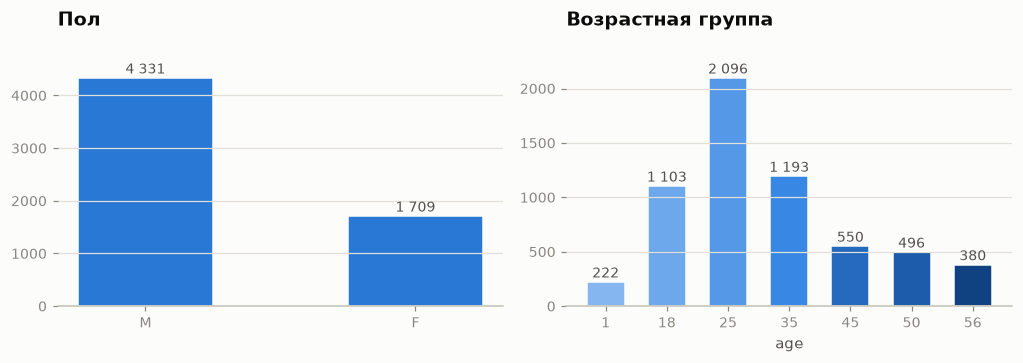

In [10]:
display(users_f.head())
uf_card = pd.Series({
    'пользователей': len(users_f),
    'покрытие пользователей из events': set(events.user_id) == set(users_f.user_id),
    'gender cardinality': users_f.gender.nunique(),
    'age cardinality': users_f.age.nunique(),
    'значения age': ', '.join(map(str, sorted(users_f.age.unique()))),
})
display(uf_card.to_frame())

gender_counts = users_f.gender.value_counts()
age_counts = users_f.age.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.4))
bars = axes[0].bar(gender_counts.index, gender_counts.values, width=0.5,
                   color=SERIES, edgecolor=SURFACE, linewidth=1)
for b, v in zip(bars, gender_counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + gender_counts.max() * 0.02,
                 kfmt(v), ha='center', fontsize=9, color=INK_2)
style(axes[0], 'Пол')
axes[0].set_ylim(0, gender_counts.max() * 1.15)

bars = axes[1].bar(age_counts.index.astype(str), age_counts.values, width=0.62,
                   color=BLUE_ORDINAL_7, edgecolor=SURFACE, linewidth=1)
for b, v in zip(bars, age_counts.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v + age_counts.max() * 0.02,
                 kfmt(v), ha='center', fontsize=9, color=INK_2)
style(axes[1], 'Возрастная группа')
axes[1].set_ylim(0, age_counts.max() * 1.15)
axes[1].set_xlabel('age')
plt.tight_layout()
plt.show()

In [11]:
user_stats = events.groupby('user_id').agg(n_inter=('item_id', 'size'), mean_rating=('rating', 'mean'))
demo = users_f.merge(user_stats, on='user_id')
by_gender = demo.groupby('gender')[['n_inter', 'mean_rating']].median()
by_age = demo.groupby('age')[['n_inter', 'mean_rating']].median()
display(pd.concat([by_gender, by_age], keys=['gender', 'age']))

n_inter  mean_rating
gender F      69.0     3.764151
       M      91.0     3.727273
age    1      69.5     3.636224
       18     88.0     3.640625
       25     99.0     3.709873
       35     84.0     3.774194
       45     73.0     3.798649
       50     76.0     3.811542
       56     56.0     3.890390

- Демография покрывает 100% пользователей из events, пропусков нет; `age` — групповой признак (значение 1 — скорее всего «до 18»), `gender` — бинарный.
- Активность и средняя оценка различаются по группам (медианы выше) — демография даёт признаки для персонализации и гипотезу demographic × genre (H5).
- Cardinality крошечная, поэтому эти признаки работают только как контекст/признаки ранжирования, а не как сегменты для отдельных моделей.

## 8. Item features: жанры

In [12]:
GENRES = [c for c in items_f.columns if c.startswith('genre_')]
genre_flags = items_f.set_index('item_id')[GENRES]
genres_per_item = genre_flags.sum(axis=1)

itf_card = pd.Series({
    'фильмов в item_features': len(items_f),
    'покрытие item из events': set(events.item_id).issubset(set(items_f.item_id)),
    'фильмов без interactions': len(set(items_f.item_id) - set(events.item_id)),
    'значения флагов': sorted(pd.unique(genre_flags.values.ravel()).tolist()),
    'жанров на фильм, min / median / max': f'{genres_per_item.min()} / {genres_per_item.median():.0f} / {genres_per_item.max()}',
})
display(itf_card.to_frame())
display(genres_per_item.value_counts().sort_index().to_frame('фильмов'))

,0
фильмов в item_features,3706
покрытие item из events,True
фильмов без interactions,16
значения флагов,"[0, 1]"
"жанров на фильм, min / median / max",1 / 1 / 6


,фильмов
1,1882
2,1293
3,416
4,100
5,14
6,1


,interactions,users (reach),mean rating
genre_4,318860,6024,3.521
genre_7,317206,6036,3.766
genre_0,230289,5999,3.491
genre_15,169453,5964,3.570
genre_14,140630,5873,3.467
genre_13,131810,5925,3.607
genre_1,119825,5856,3.476
genre_5,71325,5591,3.707
genre_10,68194,5195,3.216
genre_3,64664,5190,3.419


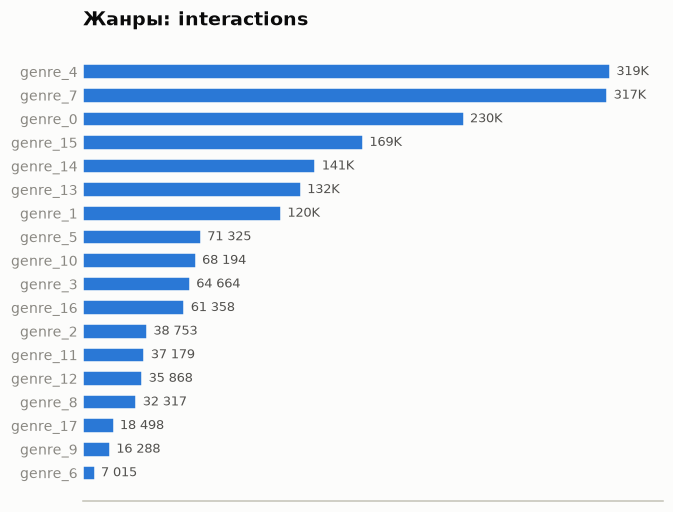

In [13]:
ev_g = events.merge(items_f, on='item_id')
g_int = ev_g[GENRES].sum()                                      # interactions по жанру
g_reach = ev_g.groupby('user_id')[GENRES].max().sum()            # пользователей, трогавших жанр
g_mean_rating = ev_g[GENRES].mul(ev_g.rating, axis=0).sum() / g_int

genre_tbl = pd.DataFrame({
    'interactions': g_int.astype(int),
    'users (reach)': g_reach.astype(int),
    'mean rating': g_mean_rating.round(3),
}).sort_values('interactions', ascending=False)
display(genre_tbl)

order = g_int.sort_values()
fig, ax = plt.subplots(figsize=(6.8, 5.4))
bars = ax.barh(order.index, order.values, height=0.62, color=SERIES, edgecolor=SURFACE, linewidth=1)
for b, v in zip(bars, order.values):
    ax.text(v + order.max() * 0.012, b.get_y() + b.get_height() / 2, kfmt(v),
            va='center', fontsize=8.5, color=INK_2)
ax.set_title('Жанры: interactions')
ax.grid(visible=False)
ax.set_xticks([])
ax.tick_params(axis='y', length=0)
ax.set_xlim(0, order.max() * 1.1)
plt.show()

- Имена жанров анонимизированы (`genre_0` … `genre_17`), но мультиномиальная структура сохранена: 1–6 жанров на фильм, медиана 1.
- Все 3690 фильмов из events покрыты фичами; 16 фильмов есть только в фичах (холодный запас для content-based кандидатов).
- Жанры сильно различаются по объёму и средней оценке -> есть материал для user genre profile, genre affinity и content-similarity кандидатов (H5), а также для `user × genre` признаков ранжирования.
- Content similarity по 18 бинарным флагам будет грубой (Jaccard/cosine на почти ортогональных векторах) — рассчитываем на неё как на дополнительный источник кандидатов, не основной.

## 9. Формат сабмита

In [14]:
display(submission.head(3))
sub_tokens = submission.item_id.str.split()
sub_card = pd.Series({
    'строк': len(submission),
    'токенов в строке': sub_tokens.apply(len).unique().tolist(),
    'покрытие пользователей из events': set(submission.user_id) == set(events.user_id),
    'уникальные токены в item_id': sorted({t for row in sub_tokens for t in row}),
})
sub_card.to_frame()

,user_id,item_id
0,0,0 1 2 3 4 5 6 7 8 9
1,1,0 1 2 3 4 5 6 7 8 9
2,2,0 1 2 3 4 5 6 7 8 9


,0
строк,6040
токенов в строке,[10]
покрытие пользователей из events,True
уникальные токены в item_id,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"


Формат: одна строка на пользователя, `item_id` — 10 айтемов через пробел. В sample это плейсхолдеры `0 1 … 9`, реальных подсказок нет. Требуется 10 фильмов каждому из 6040 пользователей.

## 10. Итоги EDA

**Данные.** 894 149 interactions, 6040 пользователей, 3690 фильмов (все с фичами), density ≈ 4.0%, пропусков и дубликатов нет; повторных пар (user, item) нет.

**Ключевые факты для дальнейших этапов:**
1. `timestamp` — позиция внутри истории пользователя, общей календарной оси нет -> глобальный temporal cutoff невозможен; фиксируем **chronological 90/10 per user** как основную валидацию (все 6040 пользователей в ground truth, cold items единицы).
2. Полнота позиций внутри историй ≈ 90% при совпадении структуры с MovieLens ML-1M -> правдоподобная гипотеза, что скрытый тест — замаскированные ~10% взаимодействий; держим её в голове при сопоставлении локальной метрики и Kaggle, но протокол валидации по ней не подстраиваем.
3. Профили длинные (медиана ~85, минимум 14) — холодных пользователей нет, персонализация доступна всем; popularity сильно скошена (топ-20% фильмов ≈ 65% interactions) -> popularity baseline заметен, но есть большая комната для персонализации.
4. Оценки смещены вверх (83.6% `>=3`, 57.5% `>=4`) -> бинаризация feedback — первая гипотеза (H1).
5. Демография (gender/age) покрывает всех пользователей и различается по активности/оценкам; 18 анонимных жанров дают контентные признаки и жанровый профиль пользователя (H5).

**Следующий шаг (этап 2 плана):** зафиксировать код сплита 90/10 per user, реализовать Recall@10 и снять E01 Global Popularity.